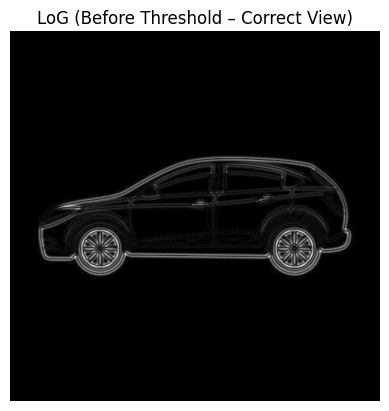

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read image
img = cv2.imread('/kaggle/input/blobdetect/car.jpg', 0)

# Gaussian Blur
blur = cv2.GaussianBlur(img, (9,9), 0)

# LoG
log = cv2.Laplacian(blur, cv2.CV_64F)

# FIX for visualization
log_abs = np.abs(log)
log_norm = cv2.normalize(log_abs, None, 0, 255, cv2.NORM_MINMAX)
log_norm = np.uint8(log_norm)

# Show
plt.imshow(log_norm, cmap='gray')
plt.title("LoG (Before Threshold – Correct View)")
plt.axis('off')
plt.show()

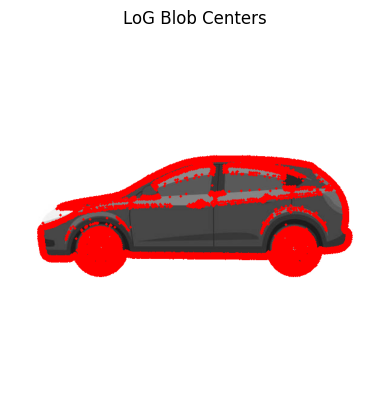

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read image
img = cv2.imread('/kaggle/input/blobdetect/car.jpg', 0)

# Apply Gaussian blur
blur = cv2.GaussianBlur(img, (9, 9), 0)

# Apply Laplacian (LoG)
log = cv2.Laplacian(blur, cv2.CV_64F)

# Take absolute value and normalize
log_abs = np.abs(log)
log_norm = cv2.normalize(log_abs, None, 0, 255, cv2.NORM_MINMAX)
log_norm = np.uint8(log_norm)

# Threshold
_, thresh = cv2.threshold(log_norm, 50, 255, cv2.THRESH_BINARY)

# Find blob centers
keypoints = cv2.findNonZero(thresh)

# Convert to color image
img_color = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)

# Mark centers in red
for p in keypoints:
    x, y = p[0]
    cv2.circle(img_color, (x,y), 2, (0,0,255), -1)

# Show result
plt.imshow(cv2.cvtColor(img_color, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.title("LoG Blob Centers")
plt.show()